# Customer Segmentation Analysis using K-Means Clustering

**Objective:** Identify distinct customer segments from mall customer data for targeted marketing strategies.

**Dataset:** Mall_Customers.csv (200 customers, 5 features)

**Method:** K-Means Clustering

## 1. Setup and Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import pickle
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

# Paths
PROJECT_ROOT = Path('..').resolve()
DATA_DIR = PROJECT_ROOT / 'data'
MODELS_DIR = PROJECT_ROOT / 'models'
OUTPUTS_DIR = PROJECT_ROOT / 'outputs'

print(f"Project root: {PROJECT_ROOT}")

Project root: D:\Magister\Semester 1\Pembelajaran Mesin\customer-segment-kmeans


In [2]:
# Load dataset
df = pd.read_csv(DATA_DIR / 'raw' / 'Mall_Customers.csv')

print(f"Dataset shape: {df.shape}")
df.head(10)

Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


## 2. Descriptive Statistics

In [3]:
# Basic information
print("Dataset Information:")
print(f"Shape: {df.shape}")
print(f"\nColumn Types:\n{df.dtypes}")
print(f"\nMissing Values:\n{df.isnull().sum()}")
print(f"\nDuplicate Rows: {df.duplicated().sum()}")

Dataset Information:
Shape: (200, 5)

Column Types:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Rows: 0


In [4]:
# Statistical summary
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [5]:
# Categorical distribution
print("Gender Distribution:")
print(df['Gender'].value_counts())
print(f"\nFemale: {df['Gender'].value_counts()['Female']} ({df['Gender'].value_counts()['Female']/len(df)*100:.1f}%)")
print(f"Male: {df['Gender'].value_counts()['Male']} ({df['Gender'].value_counts()['Male']/len(df)*100:.1f}%)")

Gender Distribution:
Gender
Female    112
Male       88
Name: count, dtype: int64

Female: 112 (56.0%)
Male: 88 (44.0%)


## 3. Exploratory Data Analysis (EDA)

In [6]:
# Statistics by gender
print("Age by Gender:")
print(df.groupby('Gender')['Age'].describe())
print("\nIncome by Gender:")
print(df.groupby('Gender')['Annual Income (k$)'].describe())
print("\nSpending Score by Gender:")
print(df.groupby('Gender')['Spending Score (1-100)'].describe())

Age by Gender:
        count       mean        std   min    25%   50%   75%   max
Gender                                                            
Female  112.0  38.098214  12.644095  18.0  29.00  35.0  47.5  68.0
Male     88.0  39.806818  15.514812  18.0  27.75  37.0  50.5  70.0

Income by Gender:
        count       mean        std   min    25%   50%    75%    max
Gender                                                              
Female  112.0  59.250000  26.011952  16.0  39.75  60.0  77.25  126.0
Male     88.0  62.227273  26.638373  15.0  45.50  62.5  78.00  137.0

Spending Score by Gender:
        count       mean       std  min   25%   50%   75%   max
Gender                                                         
Female  112.0  51.526786  24.11495  5.0  35.0  50.0  73.0  99.0
Male     88.0  48.511364  27.89677  1.0  24.5  50.0  70.0  97.0


In [7]:
# Correlation matrix
corr_matrix = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].corr()
print("Correlation Matrix:")
print(corr_matrix)

Correlation Matrix:
                             Age  Annual Income (k$)  Spending Score (1-100)
Age                     1.000000           -0.012398               -0.327227
Annual Income (k$)     -0.012398            1.000000                0.009903
Spending Score (1-100) -0.327227            0.009903                1.000000


### 3.1 Distribution Visualizations

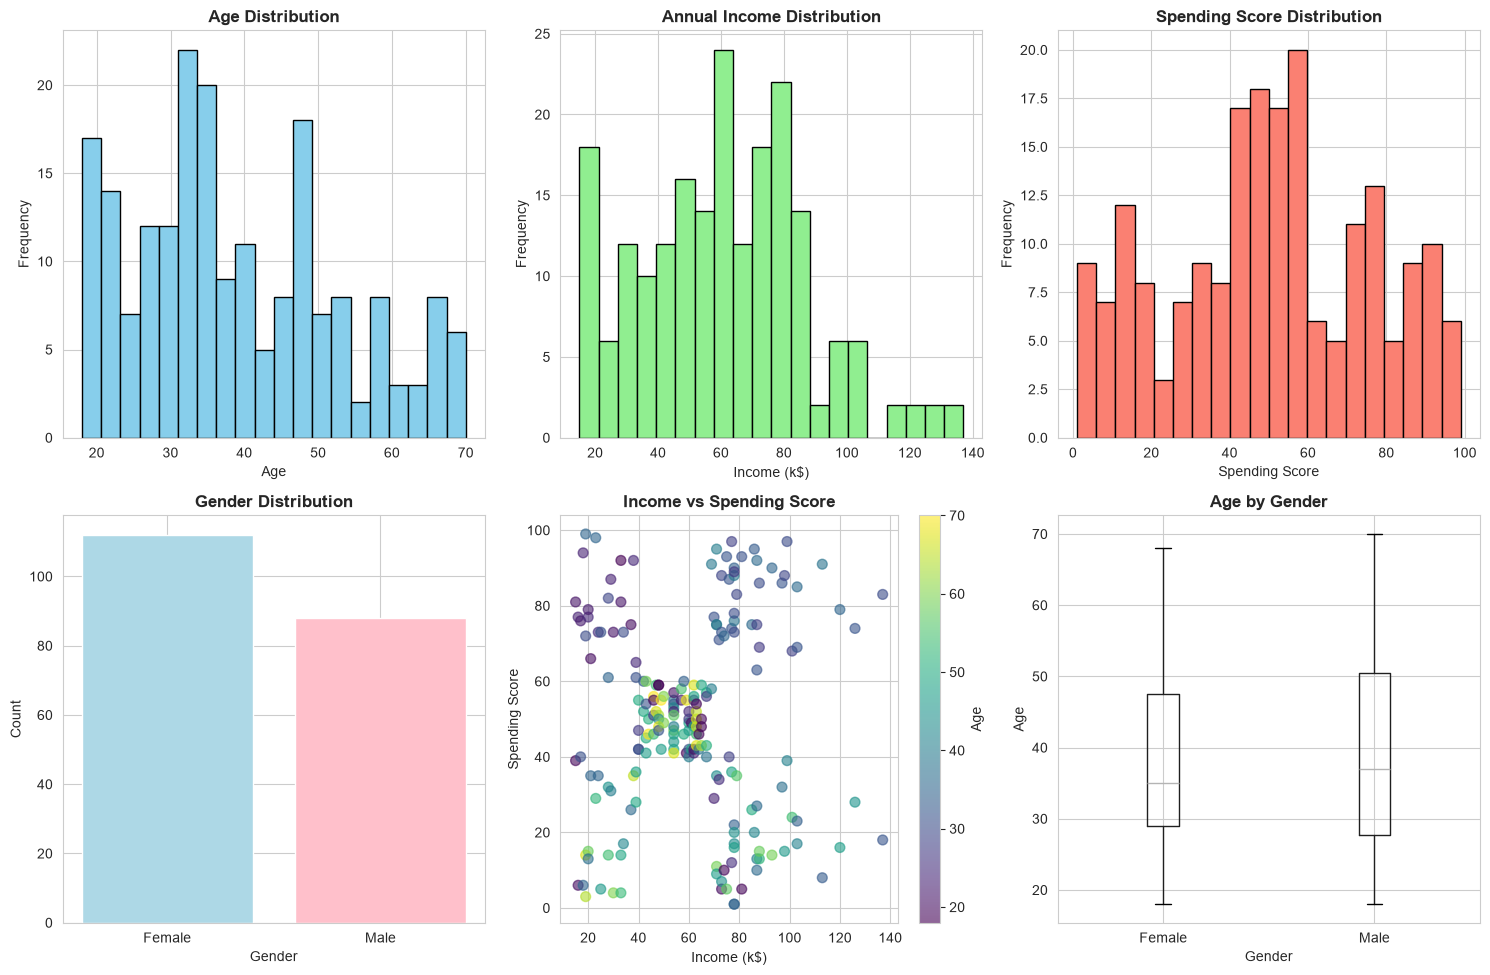

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Age distribution
axes[0, 0].hist(df['Age'], bins=20, color='skyblue', edgecolor='black')
axes[0, 0].set_title('Age Distribution', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Frequency')

# Income distribution
axes[0, 1].hist(df['Annual Income (k$)'], bins=20, color='lightgreen', edgecolor='black')
axes[0, 1].set_title('Annual Income Distribution', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Income (k$)')
axes[0, 1].set_ylabel('Frequency')

# Spending score distribution
axes[0, 2].hist(df['Spending Score (1-100)'], bins=20, color='salmon', edgecolor='black')
axes[0, 2].set_title('Spending Score Distribution', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('Spending Score')
axes[0, 2].set_ylabel('Frequency')

# Gender distribution
gender_counts = df['Gender'].value_counts()
axes[1, 0].bar(gender_counts.index, gender_counts.values, color=['lightblue', 'pink'])
axes[1, 0].set_title('Gender Distribution', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Gender')
axes[1, 0].set_ylabel('Count')

# Income vs Spending
scatter = axes[1, 1].scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], 
                            c=df['Age'], cmap='viridis', alpha=0.6, s=50)
axes[1, 1].set_title('Income vs Spending Score', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Income (k$)')
axes[1, 1].set_ylabel('Spending Score')
plt.colorbar(scatter, ax=axes[1, 1], label='Age')

# Box plot - Age by Gender
df.boxplot(column='Age', by='Gender', ax=axes[1, 2])
axes[1, 2].set_title('Age by Gender', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Gender')
axes[1, 2].set_ylabel('Age')
plt.suptitle('')

plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'eda_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

### 3.2 Correlation Heatmap

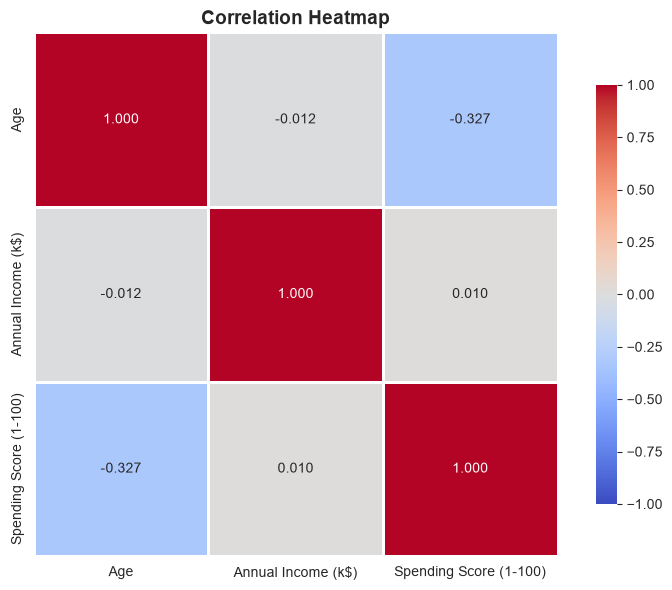

Key Insights:
- Age vs Income: -0.012 (no correlation)
- Age vs Spending: -0.327 (negative - younger customers spend more)
- Income vs Spending: 0.010 (no correlation - spending independent of income)


In [9]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8}, 
            fmt='.3f', vmin=-1, vmax=1)
plt.title('Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

print("Key Insights:")
print("- Age vs Income: -0.012 (no correlation)")
print("- Age vs Spending: -0.327 (negative - younger customers spend more)")
print("- Income vs Spending: 0.010 (no correlation - spending independent of income)")

## 4. Data Preprocessing

In [10]:
# Drop CustomerID (not predictive)
df_processed = df.drop('CustomerID', axis=1).copy()

# Encode Gender
le = LabelEncoder()
df_processed['Gender_Encoded'] = le.fit_transform(df_processed['Gender'])

print(f"Gender encoding: {dict(zip(le.classes_, le.transform(le.classes_)))}")

Gender encoding: {'Female': np.int64(0), 'Male': np.int64(1)}


In [11]:
# Select features for clustering
feature_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Gender_Encoded']
X = df_processed[feature_cols].copy()

print(f"Features selected: {feature_cols}")
print(f"Feature matrix shape: {X.shape}")
X.head()

Features selected: ['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Gender_Encoded']
Feature matrix shape: (200, 4)


,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded
0,19,15,39,1
1,21,15,81,1
2,20,16,6,0
3,23,16,77,0
4,31,17,40,0


### 4.1 Outlier Detection

In [12]:
# IQR method for outlier detection
print("Outlier Detection (IQR method):")
for col in X.columns:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = ((X[col] < (Q1 - 1.5 * IQR)) | (X[col] > (Q3 + 1.5 * IQR))).sum()
    print(f"  {col}: {outliers} outliers")

Outlier Detection (IQR method):
  Age: 0 outliers
  Annual Income (k$): 2 outliers
  Spending Score (1-100): 0 outliers
  Gender_Encoded: 0 outliers


### 4.2 Feature Scaling

In [13]:
# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)

print("Scaled Features Statistics:")
X_scaled_df.describe()

Scaled Features Statistics:


,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded
count,2.000000e+02,2.000000e+02,2.000000e+02,2.000000e+02
mean,-1.021405e-16,-2.131628e-16,-1.465494e-16,3.108624e-17
std,1.002509e+00,1.002509e+00,1.002509e+00,1.002509e+00
min,-1.496335e+00,-1.738999e+00,-1.910021e+00,-8.864053e-01
25%,-7.248436e-01,-7.275093e-01,-5.997931e-01,-8.864053e-01
50%,-2.045351e-01,3.587926e-02,-7.764312e-03,-8.864053e-01
75%,7.284319e-01,6.656748e-01,8.851316e-01,1.128152e+00
max,2.235532e+00,2.917671e+00,1.894492e+00,1.128152e+00


## 5. K-Means Clustering

### 5.1 Optimal K Selection (Elbow Method + Silhouette)

In [14]:
# Test different K values
inertias = []
silhouette_scores = []
K_range = range(2, 11)

print("Testing K values from 2 to 10...\n")
for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))
    print(f"K={k}: Inertia={kmeans.inertia_:.2f}, Silhouette Score={silhouette_scores[-1]:.3f}")

Testing K values from 2 to 10...

K=2: Inertia=588.80, Silhouette Score=0.252
K=3: Inertia=476.79, Silhouette Score=0.260
K=4: Inertia=388.72, Silhouette Score=0.298
K=5: Inertia=331.31, Silhouette Score=0.304
K=6: Inertia=276.41, Silhouette Score=0.331
K=7: Inertia=236.20, Silhouette Score=0.357
K=8: Inertia=199.75, Silhouette Score=0.388
K=9: Inertia=174.24, Silhouette Score=0.403
K=10: Inertia=152.03, Silhouette Score=0.421


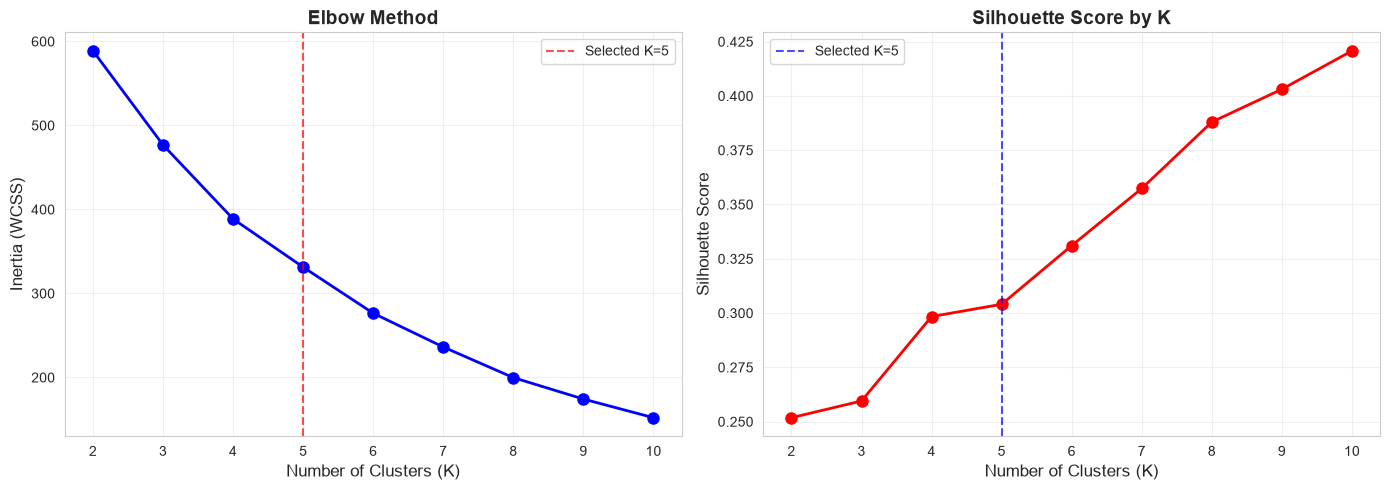

In [15]:
# Plot elbow curve and silhouette scores
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Elbow method
ax1.plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
ax1.axvline(x=5, color='red', linestyle='--', alpha=0.7, label='Selected K=5')
ax1.set_xlabel('Number of Clusters (K)', fontsize=12)
ax1.set_ylabel('Inertia (WCSS)', fontsize=12)
ax1.set_title('Elbow Method', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend()

# Silhouette score
ax2.plot(K_range, silhouette_scores, 'ro-', linewidth=2, markersize=8)
ax2.axvline(x=5, color='blue', linestyle='--', alpha=0.7, label='Selected K=5')
ax2.set_xlabel('Number of Clusters (K)', fontsize=12)
ax2.set_ylabel('Silhouette Score', fontsize=12)
ax2.set_title('Silhouette Score by K', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'elbow_silhouette.png', dpi=300, bbox_inches='tight')
plt.show()

### 5.2 Train Final Model

In [16]:
# Selected optimal K
optimal_k = 5
print(f"Optimal K selected: {optimal_k}")

# Train final model
kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
clusters = kmeans_final.fit_predict(X_scaled)

# Add cluster labels
df_processed['Cluster'] = clusters

print(f"\nModel trained with {optimal_k} clusters")
print(f"Cluster distribution:\n{df_processed['Cluster'].value_counts().sort_index()}")

Optimal K selected: 5

Model trained with 5 clusters
Cluster distribution:
Cluster
0    39
1    29
2    43
3    54
4    35
Name: count, dtype: int64


## 6. Model Evaluation

In [17]:
# Evaluation metrics
silhouette = silhouette_score(X_scaled, clusters)
davies_bouldin = davies_bouldin_score(X_scaled, clusters)
calinski_harabasz = calinski_harabasz_score(X_scaled, clusters)

print("Model Evaluation Metrics:")
print(f"\nSilhouette Score: {silhouette:.4f}")
print("  Interpretation: Moderate cluster quality (0.2-0.5 range is acceptable)")
print(f"\nDavies-Bouldin Index: {davies_bouldin:.4f}")
print("  Interpretation: Lower is better - measures cluster separation")
print(f"\nCalinski-Harabasz Index: {calinski_harabasz:.4f}")
print("  Interpretation: Higher is better - ratio of between/within cluster variance")

Model Evaluation Metrics:

Silhouette Score: 0.3041
  Interpretation: Moderate cluster quality (0.2-0.5 range is acceptable)

Davies-Bouldin Index: 1.1672
  Interpretation: Lower is better - measures cluster separation

Calinski-Harabasz Index: 68.9646
  Interpretation: Higher is better - ratio of between/within cluster variance


## 7. Cluster Analysis

In [18]:
# Cluster characteristics
cluster_summary = df_processed.groupby('Cluster')[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].agg(['mean', 'std', 'min', 'max'])
print("Cluster Characteristics:")
cluster_summary

Cluster Characteristics:


Age                   Annual Income (k$)                      \
              mean       std min max               mean        std min  max   
Cluster                                                                       
0        32.692308  3.728650  27  40          86.538462  16.312485  69  137   
1        36.482759  9.679214  19  54          89.517241  17.418424  70  137   
2        49.813953  9.474919  32  68          49.232558  15.601949  18   79   
3        24.907407  5.349197  18  35          39.722222  16.981029  15   67   
4        55.714286  9.596480  37  70          53.685714  18.714215  19   93   

        Spending Score (1-100)                     
                          mean        std min max  
Cluster                                            
0                    82.128205   9.364489  63  97  
1                    18.000000  10.579630   1  40  
2                    40.069767  15.555424   5  59  
3                    61.203704  18.420026   6  99  
4                    36.771429  17.990334   3  60

In [19]:
# Detailed cluster profiles
print("\nDetailed Cluster Profiles:\n")
print("="*60)

cluster_names = {
    0: "High Income, High Spenders",
    1: "High Income, Low Spenders",
    2: "Middle Age, Average",
    3: "Young, Moderate Spenders",
    4: "Older, Conservative"
}

for cluster_id in range(optimal_k):
    cluster_data = df_processed[df_processed['Cluster'] == cluster_id]
    print(f"\nCluster {cluster_id}: {cluster_names[cluster_id]} (n={len(cluster_data)})")
    print(f"  Age: {cluster_data['Age'].mean():.1f} ± {cluster_data['Age'].std():.1f} years")
    print(f"  Income: ${cluster_data['Annual Income (k$)'].mean():.1f}k ± ${cluster_data['Annual Income (k$)'].std():.1f}k")
    print(f"  Spending: {cluster_data['Spending Score (1-100)'].mean():.1f} ± {cluster_data['Spending Score (1-100)'].std():.1f}")
    gender_dist = cluster_data['Gender'].value_counts().to_dict()
    print(f"  Gender: {cluster_data['Gender'].mode()[0]} (Distribution: {gender_dist})")
    print("-"*60)


Detailed Cluster Profiles:


Cluster 0: High Income, High Spenders (n=39)
  Age: 32.7 ± 3.7 years
  Income: $86.5k ± $16.3k
  Spending: 82.1 ± 9.4
  Gender: Female (Distribution: {'Female': 21, 'Male': 18})
------------------------------------------------------------

Cluster 1: High Income, Low Spenders (n=29)
  Age: 36.5 ± 9.7 years
  Income: $89.5k ± $17.4k
  Spending: 18.0 ± 10.6
  Gender: Female (Distribution: {'Female': 16, 'Male': 13})
------------------------------------------------------------

Cluster 2: Middle Age, Average (n=43)
  Age: 49.8 ± 9.5 years
  Income: $49.2k ± $15.6k
  Spending: 40.1 ± 15.6
  Gender: Female (Distribution: {'Female': 43})
------------------------------------------------------------

Cluster 3: Young, Moderate Spenders (n=54)
  Age: 24.9 ± 5.3 years
  Income: $39.7k ± $17.0k
  Spending: 61.2 ± 18.4
  Gender: Female (Distribution: {'Female': 32, 'Male': 22})
------------------------------------------------------------

Cluster 4: Older, Conservativ

## 8. Cluster Visualization

### 8.1 2D Scatter Plots

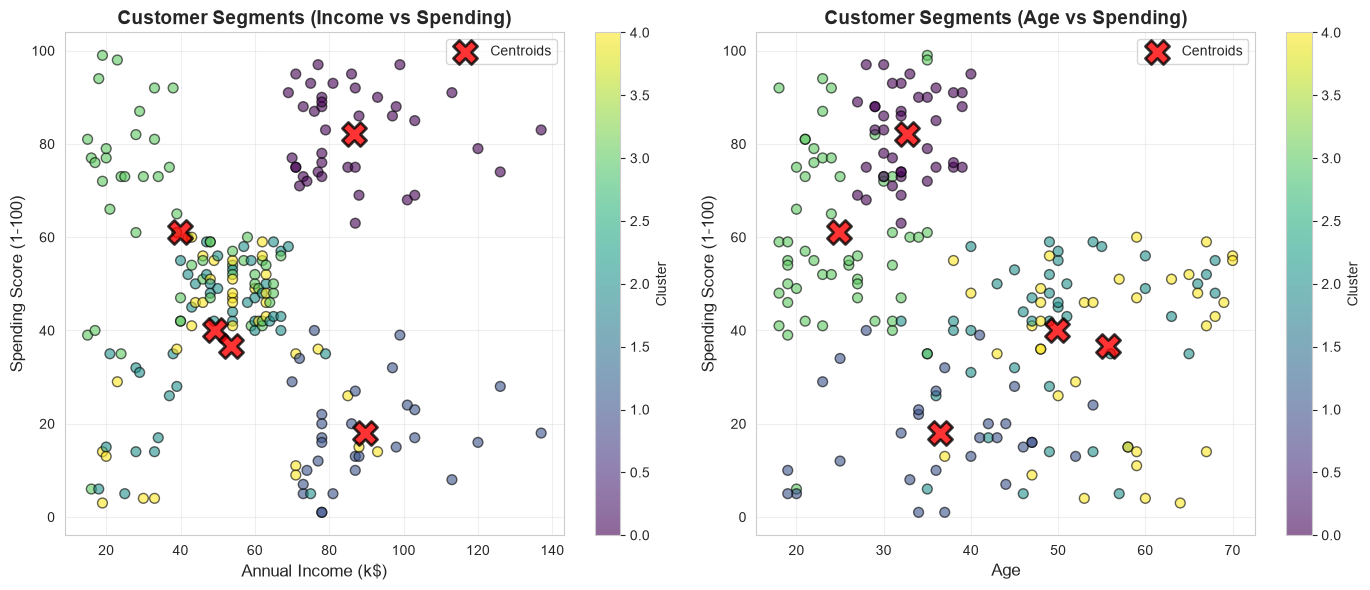

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Income vs Spending Score
scatter1 = axes[0].scatter(df_processed['Annual Income (k$)'], 
                           df_processed['Spending Score (1-100)'],
                           c=df_processed['Cluster'], cmap='viridis', 
                           s=50, alpha=0.6, edgecolors='black')
centers_income = kmeans_final.cluster_centers_[:, 1] * scaler.scale_[1] + scaler.mean_[1]
centers_spending = kmeans_final.cluster_centers_[:, 2] * scaler.scale_[2] + scaler.mean_[2]
axes[0].scatter(centers_income, centers_spending,
                c='red', s=300, alpha=0.8, marker='X', edgecolors='black', linewidths=2,
                label='Centroids')
axes[0].set_xlabel('Annual Income (k$)', fontsize=12)
axes[0].set_ylabel('Spending Score (1-100)', fontsize=12)
axes[0].set_title('Customer Segments (Income vs Spending)', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
plt.colorbar(scatter1, ax=axes[0], label='Cluster')

# Age vs Spending Score
scatter2 = axes[1].scatter(df_processed['Age'], 
                           df_processed['Spending Score (1-100)'],
                           c=df_processed['Cluster'], cmap='viridis', 
                           s=50, alpha=0.6, edgecolors='black')
centers_age = kmeans_final.cluster_centers_[:, 0] * scaler.scale_[0] + scaler.mean_[0]
axes[1].scatter(centers_age, centers_spending,
                c='red', s=300, alpha=0.8, marker='X', edgecolors='black', linewidths=2,
                label='Centroids')
axes[1].set_xlabel('Age', fontsize=12)
axes[1].set_ylabel('Spending Score (1-100)', fontsize=12)
axes[1].set_title('Customer Segments (Age vs Spending)', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.colorbar(scatter2, ax=axes[1], label='Cluster')

plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'cluster_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

### 8.2 3D Visualization

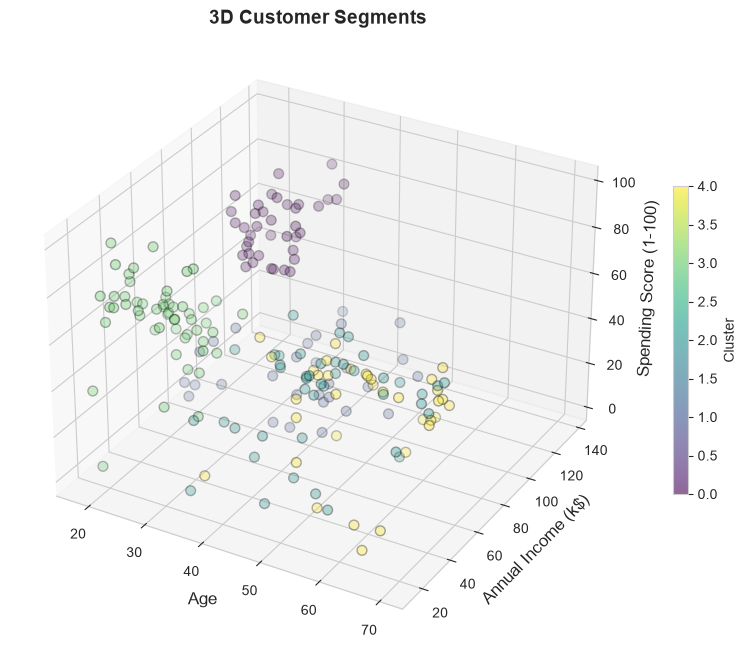

In [21]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(df_processed['Age'], 
                     df_processed['Annual Income (k$)'],
                     df_processed['Spending Score (1-100)'],
                     c=df_processed['Cluster'], cmap='viridis',
                     s=50, alpha=0.6, edgecolors='black')

ax.set_xlabel('Age', fontsize=12)
ax.set_ylabel('Annual Income (k$)', fontsize=12)
ax.set_zlabel('Spending Score (1-100)', fontsize=12)
ax.set_title('3D Customer Segments', fontsize=14, fontweight='bold')
plt.colorbar(scatter, ax=ax, label='Cluster', shrink=0.5)

plt.savefig(OUTPUTS_DIR / 'cluster_3d.png', dpi=300, bbox_inches='tight')
plt.show()

## 9. Save Models and Results

In [22]:
# Save model
with open(MODELS_DIR / 'kmeans_model.pkl', 'wb') as f:
    pickle.dump(kmeans_final, f)
print(f"Model saved: {MODELS_DIR / 'kmeans_model.pkl'}")

# Save scaler
with open(MODELS_DIR / 'scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print(f"Scaler saved: {MODELS_DIR / 'scaler.pkl'}")

# Save label encoder
with open(MODELS_DIR / 'label_encoder.pkl', 'wb') as f:
    pickle.dump(le, f)
print(f"Label encoder saved: {MODELS_DIR / 'label_encoder.pkl'}")

# Save segmented data
df_processed.to_csv(DATA_DIR / 'processed' / 'customer_segments.csv', index=False)
print(f"Segmented data saved: {DATA_DIR / 'processed' / 'customer_segments.csv'}")

Model saved: D:\Magister\Semester 1\Pembelajaran Mesin\customer-segment-kmeans\models\kmeans_model.pkl
Scaler saved: D:\Magister\Semester 1\Pembelajaran Mesin\customer-segment-kmeans\models\scaler.pkl
Label encoder saved: D:\Magister\Semester 1\Pembelajaran Mesin\customer-segment-kmeans\models\label_encoder.pkl
Segmented data saved: D:\Magister\Semester 1\Pembelajaran Mesin\customer-segment-kmeans\data\processed\customer_segments.csv


## 10. Business Insights & Recommendations

### Key Findings:

1. **5 Distinct Customer Segments Identified**
   - Clear separation based on income, age, and spending behavior
   - Gender plays a secondary role in segmentation

2. **Income Does Not Predict Spending**
   - Correlation between income and spending: 0.010 (negligible)
   - High-income customers can be low or high spenders
   - Psychological factors matter more than income

3. **Age Influences Spending**
   - Negative correlation: -0.327
   - Younger customers (20-35) tend to have higher spending scores
   - Older customers (50+) more conservative in spending

### Marketing Recommendations:

**Cluster 0 - High Income, High Spenders (19.5%)**
- Premium tier customers
- Strategy: Luxury products, VIP programs, exclusive events
- High ROI potential

**Cluster 1 - High Income, Low Spenders (14.5%)**
- Untapped potential
- Strategy: Value propositions, quality messaging, investment products
- Focus on converting to high spenders

**Cluster 2 - Middle Age, Average (21.5%)**
- Stable customer base (100% Female)
- Strategy: Family-oriented products, loyalty programs
- Retention focus

**Cluster 3 - Young, Moderate Spenders (27.0%)**
- Largest segment
- Strategy: Trendy products, social media marketing, flexible payments
- Build long-term loyalty

**Cluster 4 - Older, Conservative (17.5%)**
- Traditional approach (100% Male)
- Strategy: Reliability focus, traditional marketing, senior discounts
- Lower acquisition cost strategy

## Summary

**Model Performance:**
- Silhouette Score: 0.304 (moderate cluster quality)
- Davies-Bouldin Index: 1.167 (good separation)
- Calinski-Harabasz: 68.96 (reasonable definition)

**Deliverables:**
- Trained K-Means model with 5 clusters
- Customer segmentation with actionable insights
- Interactive dashboard for real-time predictions
- Marketing strategies for each segment